# Multiline TRL

Multiline TRL is a two-port VNA calibration utilizing at least two transmission lines with different physical lengths and at least one reflective standard that is identical on both ports. The electrical parameters of the lines don't need to be known, but the transmission lines should have identical construction (same propagation constant and characteristic impedance). The reflect standard reflection coefficient doesn't need to be known exactly, phase needs to be known with 90 degree accuracy.

If the measured phase differences of the lines is a multiple of 180 degrees the calibration is singular. The calibration accuracy is worse the closer the line measurement phases are to the singularities, the best accuracy is obtained in the two lines case when the phase difference is 90 degrees. Multiple lines can be used to extend the frequency range where the calibration is accurate.

skrf has two implementations: the NIST-style multiline calibration (`NISTMultilineTRL`) and the TUG multiline calibration (`TUGMultilineTRL`). They use the same standards and give the same answer (most of the time), they differ in how the measurement noise impact the result, so this example runs the two side by side.

All data used in this example is generated with skrf, and the code for it is given at the start. The notebook then demonstrates how to use both methods and compares different combinations of lines to show how the calibration accuracy improves with the number of lines. Lastly, a Monte Carlo analysis compares the two methods.

## Setup

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

import skrf
from skrf.calibration import NISTMultilineTRL, TUGMultilineTRL, terminate
from skrf.media import CPW, Coaxial
from skrf.network import two_port_reflect

skrf.stylely()

## Simulation to generate the input data

Here is how we make the data used in the rest of the example.

### Create frequency and Media 

In [2]:
freq = skrf.Frequency(1, 125, 249, 'GHz')

# CPW media used for DUT and the calibration standards
cpw = CPW(freq, w=49.1e-6, s=25.5e-6, ep_r=9.9,
                     t=4.9e-6, rho=1/4.11e7)
print(cpw.z0[0])

# 1.0 mm coaxial media for calibration error boxes
coax1mm = Coaxial(freq, z0_port=50, Dint=0.434e-3, Dout=1.0e-3, sigma=1e8)
print(coax1mm.z0[0])

f_ghz = cpw.frequency.f*1e-9

(45.65554776395502+0j)
(50.20564772916889-0.15748463048337036j)


/home/alex/code/scikit-rf-docs/skrf/media/cpw.py:240: RuntimeWarning: Conductor loss calculation invalid for lineheight t (4.9e-06)  < 3 * skin depth (2.4825569540602707e-06)
  self.alpha_conductor, self.alpha_dielectric = self.analyse_loss(


### Make realistic looking error networks.

Propagation constant determination is iterative and doesn't work as well when the error networks are randomly generated

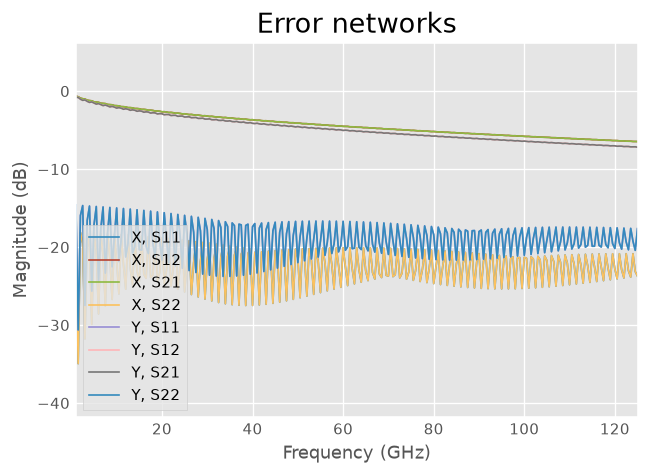

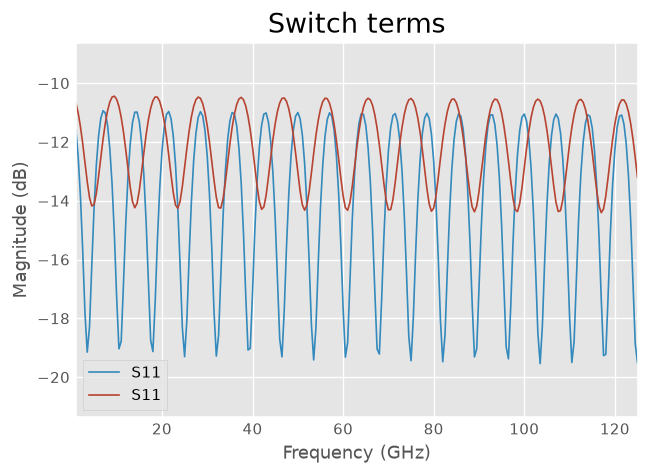

In [3]:
X = coax1mm.line(1, 'm', z0=58, name='X')
Y = coax1mm.line(1.1, 'm', z0=40, name='Y')

plt.figure()
plt.title('Error networks')
X.plot_s_db()
Y.plot_s_db()

# Realistic looking switch terms
gamma_f = coax1mm.delay_load(0.2, 21e-3, 'm', z0=60)
gamma_r = coax1mm.delay_load(0.25, 16e-3, 'm', z0=56)

plt.figure()
plt.title('Switch terms')
gamma_f.plot_s_db()
gamma_r.plot_s_db()

### Generate Fictitious measurements

In [4]:
# Lengths of the lines used in the calibration, units are in meters
line_len = [300e-6, 1200e-6, 2950e-6, 3550e-6, 5050e-6]
lines = [cpw.line(x, 'm') for x in line_len]

# Attenuator with mismatched feed lines
dut_feed = cpw.line(1.5e-3, 'm', z0=60)
dut = dut_feed**cpw.attenuator(-10)**dut_feed

res_50ohm = cpw.resistor(50) ** cpw.short(nports=2) ** cpw.resistor(50)

# Through and non-ideal short, 75 um behind the middle of the thru.
# Real reflection coefficient is solved during the calibration

short = cpw.delay_short(75e-6, 'm')

actuals = [
    cpw.thru(),
    two_port_reflect(short, short),
    ]

actuals.extend(lines)

# Measured
measured = [X**k**Y for k in actuals]

# Switch termination
measured = [terminate(m, gamma_f, gamma_r) for m in measured]

# Add little noise to the measurements
for m in measured:
    m.add_noise_polar(0.001, 0.1)

names = ['thru', 'reflect', 'line300um', 'line1200um', 'line2950um',
         'line3550um', 'line5050um']
for k,name in enumerate(names):
    measured[k].name=name


# Noiseless DUT so that all the noise will be from the calibration
dut_meas = terminate(X**dut**Y, gamma_f, gamma_r)
dut_meas.name = 'DUT'

res_50ohm_meas = terminate(X**res_50ohm**Y, gamma_f, gamma_r)
res_50ohm_meas.name = 'res_50ohm'

##  Simple Multiline TRL

The two classes take the same information, but they group it differently. `NISTMultilineTRL` takes one flat list of `measured` standards, thru first, then the reflects, then the lines. `TUGMultilineTRL` keeps the lines and the reflects in separate arguments, and the first line is taken as the thru.

Largest difference between the two: 1.09e-04


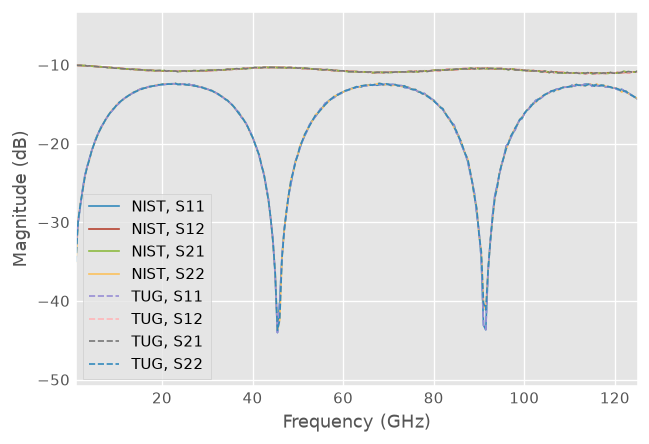

In [5]:
# define the line lengths in meters (including thru)
l = [0, 300e-6, 1200e-6, 2950e-6, 3550e-6, 5050e-6]

# Do the calibration
cal = NISTMultilineTRL(
    measured = measured,  # Measured standards
    Grefls = [-1], # Reflection coefficient of the reflect, -1 for short
    l = l,         # Lengths of the lines
    refl_offset = 75e-6, # Reflect offset from the reference plane
    er_est = 5,    # Estimate of transmission line effective permittivity
    switch_terms = (gamma_f, gamma_r) # Switch terms
    )

# The same calibration with the TUG method
cal_tug = TUGMultilineTRL(
    line_meas = [measured[0]] + measured[2:], # Measured lines, thru first
    line_lengths = l,      # Lengths of the lines
    reflect_meas = [measured[1]], # Measured reflect
    reflect_est = [-1],    # Reflection coefficient of the reflect, -1 for short
    reflect_offset = 75e-6, # Reflect offset from the reference plane
    er_est = 5,            # Estimate of transmission line effective permittivity
    switch_terms = (gamma_f, gamma_r) # Switch terms
    )

# Correct the DUT using the above calibrations
corrected = cal.apply_cal(dut_meas)
corrected.name = 'NIST'
corrected.plot_s_db()

corrected_tug = cal_tug.apply_cal(dut_meas)
corrected_tug.name = 'TUG'
corrected_tug.plot_s_db(linestyle='--')

print(f'Largest difference between the two: {abs(corrected.s - corrected_tug.s).max():.2e}')

The two methods sit on top of each other.

## Compare calibrations with different combinations of lines

Here we loop through different line combinations to demonstrate the difference in the calibration accuracy.

In [6]:
# Run multiline TRL calibration with different combinations of lines

cals = []
cals_tug = []
duts = []

line_combinations = [[0], [4], [0,4], [0,1,2,3,4]]

for used_lines in line_combinations:

    # Thru and reflect, plus the lines being used
    m = measured[:2] + [measured[2:][i] for i in used_lines]

    # Add thru length to list of line lengths
    lc = [l[0]] + [l[1:][i] for i in used_lines]

    # Do the calibration
    cal = NISTMultilineTRL(
        measured = m,  # Measured standards
        Grefls = [-1], # Reflection coefficient of the reflect, -1 for short
        l = lc,        # Lengths of the lines
        refl_offset = 75e-6, # Reflect offset from the reference plane
        er_est = 5,    # Estimate of transmission line effective permittivity
        switch_terms = (gamma_f, gamma_r) # Switch terms
        )

    # The same lines with the TUG method
    cal_t = TUGMultilineTRL(
        line_meas = [m[0]] + m[2:],
        line_lengths = lc,
        reflect_meas = [m[1]],
        reflect_est = [-1],
        reflect_offset = 75e-6,
        er_est = 5,
        switch_terms = (gamma_f, gamma_r)
        )

    # Correct the DUT using the above calibration
    corrected = cal.apply_cal(dut_meas)
    corrected.name = f'DUT, lines {used_lines}'

    duts.append(corrected)
    cals.append(cal)
    cals_tug.append(cal_t)

### Transmission of the corrected DUT
Plot the corrected DUT calibrated with different combination of calibration lines.

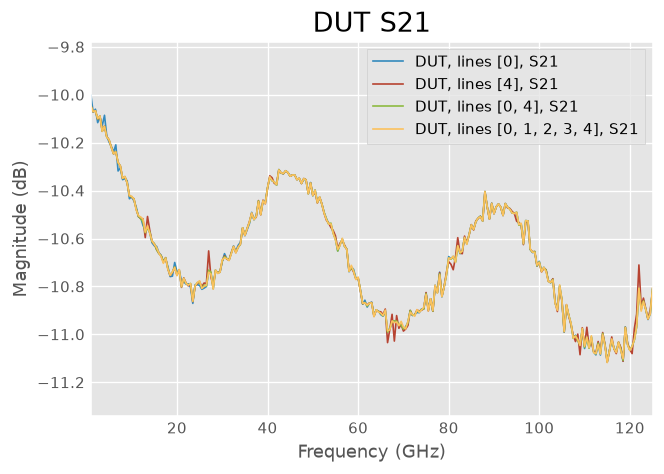

In [7]:
plt.figure()
plt.title('DUT S21')
for dut in duts:
    dut.plot_s_db(m=1, n=0)

### S11 of corrected DUT with different amount of calibration lines

S11 shows bigger changes.

* With one short line low frequencies are very noisy
* With only the long line the calibration is very inaccurate at frequencies where the phase difference of the thru and line is close to a multiple of 180 degrees
* With both lines calibration accuracy is good everywhere

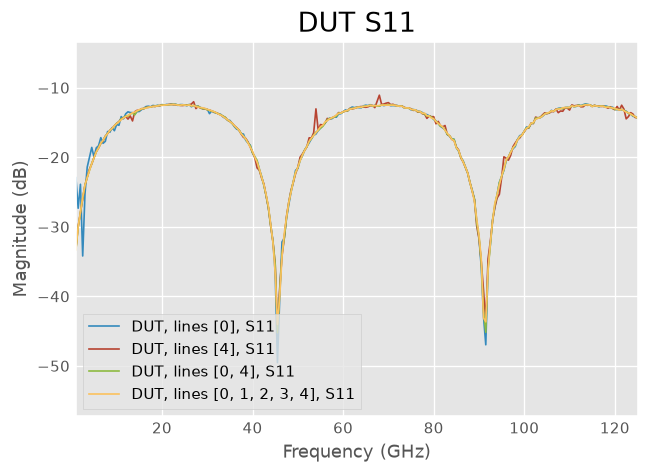

In [8]:
plt.figure()
plt.title('DUT S11')
for dut in duts:
    dut.plot_s_db(m=0, n=0)

### Normalized standard deviation of different calibrations

Normalized standard deviation can be used to measure the accuracy of the calibration. Lower number means calibration is less sensitive to the measurement noise.

 * TRL calibration with one 90 degrees long line has normalized standard deviation of 1.
 * TRL calibration with one 180 degree long lossless line is singular and has infinite normalized standard deviation.
 * With multiple lines normalized standard deviation less than one is possible.

Note that the nstd is normalized such that it doesn't consider the actual measurement noise. It's calculated only from the solved propagation constant and line lengths. The threshold of how large it can be depends on the DUT being measured, measurement noise and the required accuracy of the measurement. If there are large spikes, such as are visible in the long line case below, that's a sign that the calibration is very close to singular at that frequency and the measurement accuracy is going to be poor.

The TUG method reports the same thing through the eigenvalue $\lambda$ of its weighted eigenvalue problem, where a small eigenvalue means a sensitive calibration. For $N$ lines (thru included) the two are related by $\mathrm{nstd} \approx \sqrt{2N/\lambda}$. The dashed lines below are the TUG eigenvalue converted this way.

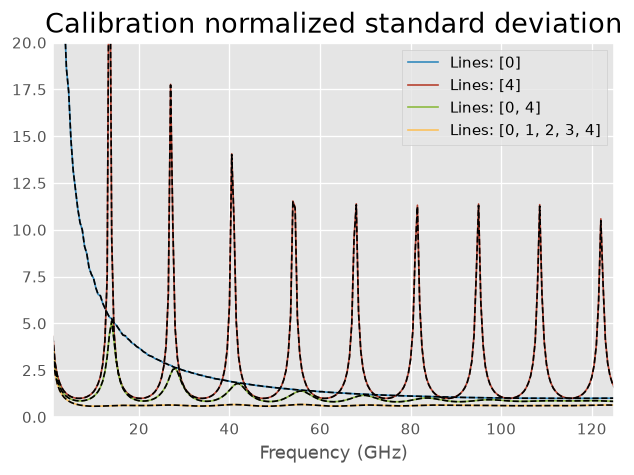

In [9]:
f_ghz = dut.frequency.f_scaled

plt.figure()
plt.title('Calibration normalized standard deviation')
for e, cal in enumerate(cals):
    plt.plot(f_ghz, cal.nstd, label=f'Lines: {line_combinations[e]}')

# The TUG eigenvalue converted to the same scale
for e, cal_t in enumerate(cals_tug):
    N = len(line_combinations[e]) + 1
    plt.plot(f_ghz, np.sqrt(2*N/cal_t.lambd), 'k--', lw=1)

plt.ylim([0,20])
plt.legend(loc='upper right')
dut.frequency.labelXAxis()

## Calculate effective complex relative permittivity of transmission lines used in the calibration

Effective complex relative permittivity $\epsilon_{r,eff}$ of a transmission line is related to the propagation constant $\gamma$ as:

$\gamma = \frac{2\pi f}{c}\sqrt{\epsilon_{r,eff}}$, where $c$ equals the speed of light and $f$ is frequency.

In general it's a complex value with the imaginary part indicating losses.

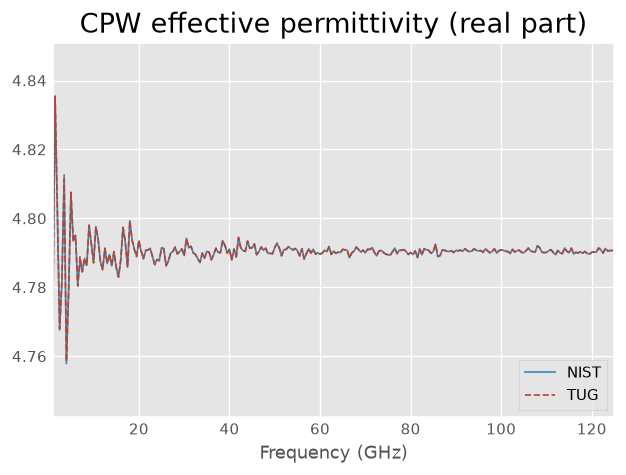

In [10]:
# Get the cal with all the lines
cal = cals[-1]
cal_tug = cals_tug[-1]

plt.figure()
plt.title('CPW effective permittivity (real part)')
plt.plot(f_ghz, cal.er_eff.real, label='NIST')
plt.plot(f_ghz, cal_tug.er_eff.real, '--', label='TUG')
plt.xlabel('Frequency (GHz)')
plt.legend(loc='lower right')

TRL calibration accuracy is the best when line length difference is 90 degrees. Solved propagation constant and effective permittivity however are more accurate the bigger the line length difference is. At low frequencies the estimate is noisier due to the line phase difference being small.

## Plot the phase of the solved reflection coefficient

Applying the calibration to the measured reflect standard we can get the calibrated S-parameters of the unknown reflect.

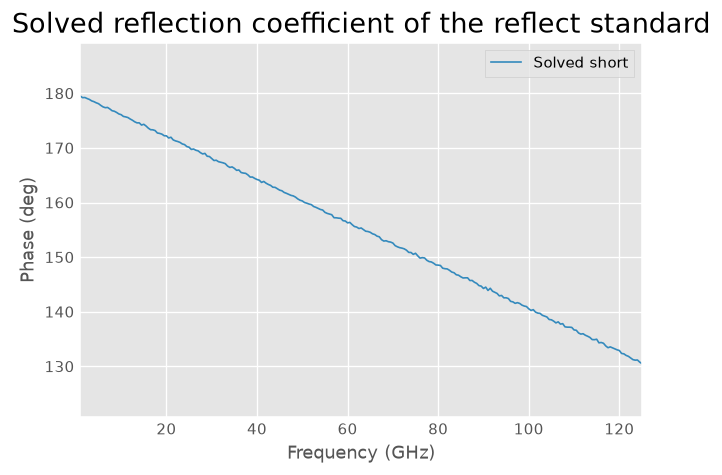

In [11]:
plt.figure()
plt.title('Solved reflection coefficient of the reflect standard')
cal.apply_cal(measured[1]).plot_s_deg(n=0, m=0, label='Solved short')

## Reference plane shift

Because propagation constant of the media is solved during the calibration it's possible to shift the reference plane by a specified distance.

The reference plane shift can be specified with `ref_plane` argument. The shift should be specified in meters, negative lengths is towards the VNA. By default the same shift is applied to both ports. Unequal shift on the two ports is supported by passing a two element list. Both classes take the same argument.

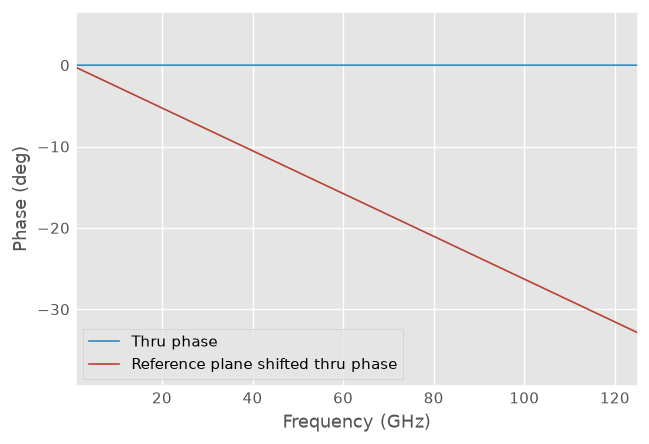

In [12]:
cal_shift = NISTMultilineTRL(
    measured = measured,  # Measured standards
    Grefls = [-1], # Reflection coefficient of the reflect, -1 for short
    l = l,         # Lengths of the lines
    refl_offset = 75e-6, # Reflect offset from the reference plane
    er_est = 5,    # Estimate of transmission line effective permittivity
    switch_terms = (gamma_f, gamma_r), # Switch terms
    # Shift reference planes towards VNA by this amount (in m) on both ports
    ref_plane = -50e-6
    )

# Correct the DUT using the above calibration
corrected_thru = cal.apply_cal(measured[0])
corrected_thru_shifted = cal_shift.apply_cal(measured[0])

corrected_thru.plot_s_deg(m=1, n=0, label='Thru phase')
corrected_thru_shifted.plot_s_deg(m=1, n=0, label='Reference plane shifted thru phase')

## Calibration reference impedance renormalization

The reference impedance of the calibration is by default the transmission line characteristic impedance. If we know the actual characteristic impedance of the lines we can give it to the calibration routine with the `z0_line` argument to renormalize the measured S-parameters to a fixed reference `z0_ref`.

If the conductance per unit length (G) is much lower than the capacitive reactance per unit length ($j\omega C_0$), the characteristic impedance of the transmission line can be written in terms of the propagation constant $\gamma$ and capacitance per unit length $C_0$:

$Z_0 = \gamma/(j 2 \pi f C_0)$

If $C_0$ is known it can be given to the calibration routine with `c0` parameter to renormalize the calibration reference impedance to `z0_ref` (defaults to 50 ohms) assuming G = 0.
If the line is lossy the characteristic impedance is complex valued and giving a single `c0` instead of a fixed `z0_line` is usually more accurate.

In this case we know that the line characteristic impedance is actually 45.7 ohms. To renormalize the calibration from 45.7 ohms to 50 ohms we need to give `z0_line=45.7` argument to the calibration routine. With `TUGMultilineTRL` the same is done afterwards with `cal.renormalize(45.7, 50)`.

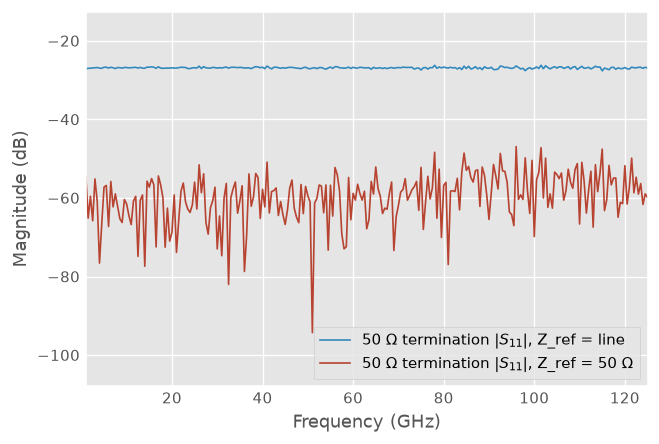

In [13]:
cal_ref = NISTMultilineTRL(
    measured = measured,  # Measured standards
    Grefls = [-1], # Reflection coefficient of the reflect, -1 for short
    l = l,         # Lengths of the lines
    refl_offset = 75e-6, # Reflect offset from the reference plane
    er_est = 5,    # Estimate of transmission line effective permittivity
    switch_terms = (gamma_f, gamma_r), # Switch terms
    z0_line = 45.7, # Line actual characteristic impedance
    z0_ref = 50 # Calibration reference impedance
    )

cal.apply_cal(res_50ohm_meas).s11.plot_s_db(label=r'50 $\Omega$ termination |$S_{11}$|, Z_ref = line')
cal_ref.apply_cal(res_50ohm_meas).s11.plot_s_db(label=r'50 $\Omega$ termination |$S_{11}$|, Z_ref = 50 $\Omega$')

After renormalization the 50 ohm termination measurement shows good matching. It's not perfectly matched due to the noise in the measurements.

### Calibration without reflect measurement

One nice feature of `TUGMultilineTRL` is that you can use only line standards if you only care about the propagation constant and S21 and S12 of the calibrated DUT. However, to obtain correct S11 and S22 values of the calibrated DUT, you also need to provide measurement of the reflect standard. This can be seen in the example below, where the phase of S11 does not overlap when using and not using the reflect standard. Note, if you do include the reflect standard, `TUGMultilineTRL` method also offers you the capability to provide multiple reflect measurements.

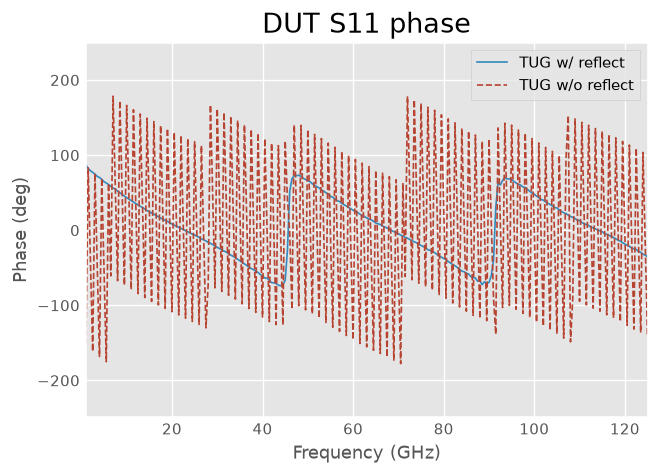

In [14]:
# TUG multiline without reflect measurement
cal_no_reflect = TUGMultilineTRL(
        line_meas = [measured[0]] + measured[2:],
        line_lengths = l,
        er_est = 5,
        switch_terms = (gamma_f, gamma_r)
        )

plt.figure()
plt.title('DUT S11 phase')
cal_tug.apply_cal(dut_meas).plot_s_deg(m=0, n=0, label='TUG w/ reflect')
cal_no_reflect.apply_cal(dut_meas).plot_s_deg(m=0, n=0, linestyle='--', label='TUG w/o reflect')

## Monte Carlo analysis - NIST vs TUG

Using MC analysis, we generate synthetic data of the standards with random noise and repeat the process multiple times, each time with a new noise sample. At each trial, we also compute the calibrated DUT, which we use to calculate the mean absolute error (MAE) of the calibration method. The general definition of MAE is as follows:

$$
\text{MAE} = \frac{1}{M}\sum_{i=1}^{M} |x_i - x_\mathrm{true}|
$$

where $x_i$ is the $i$-th MC trial and $x_\mathrm{true}$ is the true value. As the reference true value we use the DUT corrected with the measurements generated above, before the Monte Carlo noise is added. This runs both calibrations 100 times over the full frequency grid, so expect it to take about a minute.

In [15]:
# Monte Carlo Analysis
print('MC starts: ')
M = 100 # number of trials
mag_std = 0.05 # std of magnitude (linear)
phase_std = 20 # std of phase (degrees)

# Reference value, both methods agree on the unmodified measurements
dut_ideal = cal_tug.apply_cal(dut_meas)

mae_nist = 0
mae_tug  = 0

for inx in range(M):
    # add noise (make sure to copy and not override the original data)
    measured_n = [NW.copy() for NW in measured]
    for NW in measured_n:
        NW.add_noise_polar(mag_std, phase_std)

    # NIST multiline TRL
    cal_n = NISTMultilineTRL(measured=measured_n, Grefls=[-1], l=l,
                refl_offset=75e-6, er_est=5, switch_terms=(gamma_f, gamma_r))
    mae_nist = mae_nist + abs(cal_n.apply_cal(dut_meas).s - dut_ideal.s)/M

    # TUG multiline TRL
    cal_t = TUGMultilineTRL(line_meas=[measured_n[0]]+measured_n[2:], line_lengths=l,
                reflect_meas=[measured_n[1]], reflect_est=[-1], reflect_offset=75e-6,
                er_est=5, switch_terms=(gamma_f, gamma_r))
    mae_tug = mae_tug + abs(cal_t.apply_cal(dut_meas).s - dut_ideal.s)/M

    print(f'MC Index: {inx+1}/{M} done.', end='\r', flush=True)

MC starts: 


Finally, we compute and plot the MAE. The results show that TUG method on average has a lower error compared to the NIST method.

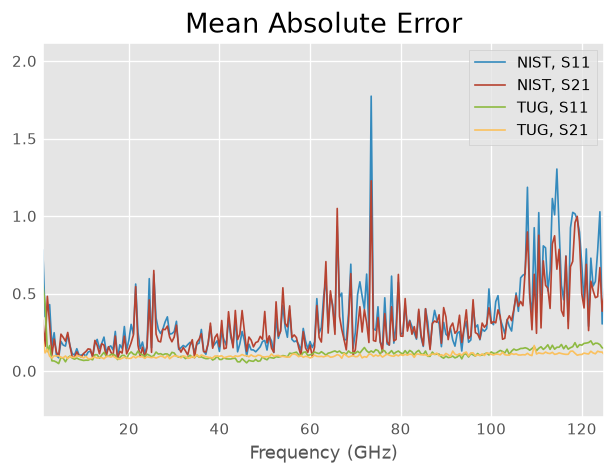

In [16]:
plt.figure()
plt.title('Mean Absolute Error')
plt.plot(f_ghz, mae_nist[:,0,0], label='NIST, S11')
plt.plot(f_ghz, mae_nist[:,1,0], label='NIST, S21')
plt.plot(f_ghz, mae_tug[:,0,0], label='TUG, S11')
plt.plot(f_ghz, mae_tug[:,1,0], label='TUG, S21')
plt.legend(loc='upper right')
dut_meas.frequency.labelXAxis()